In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import backtesting as bt
from statsmodels.tsa.stattools import coint
import numpy as np

data = yf.download(['V', 'MA'], start='2024-01-01', end='2026-11-01')['Close']
print(data.head())
print(data)

/home/nils/Desktop/Projects/Stockmarket_Trading/.venv/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/nils/Desktop/Projects/Stockmarket_Trading/.venv/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/nils/Desktop/Projects/Stockmarket_Trading/.venv/lib/python3.12/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew

Ticker              MA           V
Date                              
2024-01-02  414.403412  253.571808
2024-01-03  411.338806  252.699997
2024-01-04  412.321014  254.296631
2024-01-05  411.977295  254.374985
2024-01-08  415.145111  257.166687
Ticker              MA           V
Date                              
2024-01-02  414.403412  253.571808
2024-01-03  411.338806  252.699997
2024-01-04  412.321014  254.296631
2024-01-05  411.977295  254.374985
2024-01-08  415.145111  257.166687
...                ...         ...
2026-10-26  613.500000  404.160004
2026-10-27  609.849976  401.859985
2026-10-28  610.309998  400.600006
2026-10-29  635.700012  410.540009
2026-10-30  638.010010  413.589996

[711 rows x 2 columns]



/home/nils/Desktop/Projects/Stockmarket_Trading/.venv/lib/python3.12/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/home/nils/Desktop/Projects/Stockmarket_Trading/.venv/lib/python3.12/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)


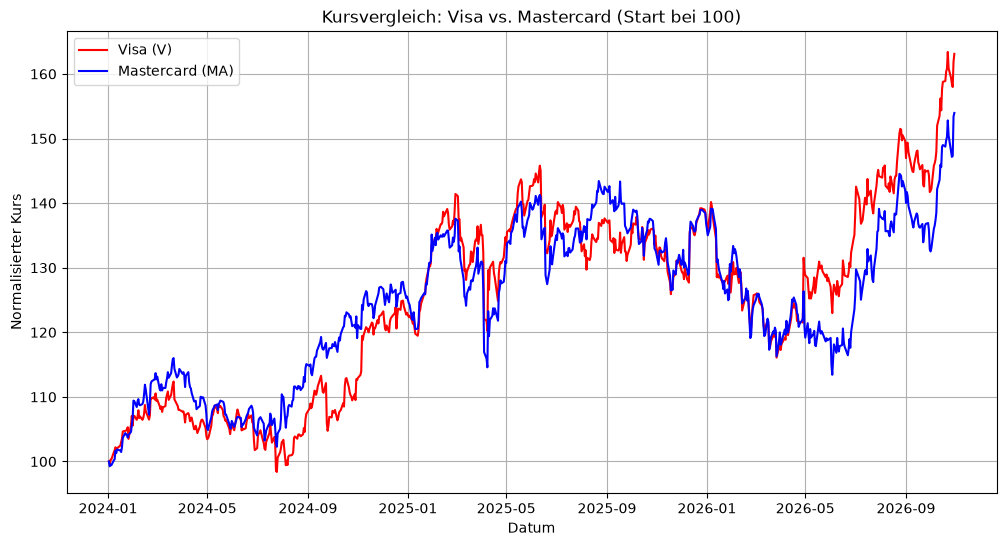

In [28]:
data_norm = (data / data.iloc[0]) * 100
plt.figure(figsize=(12, 6))
plt.plot(data_norm['V'], label='Visa (V)', color='red')
plt.plot(data_norm['MA'], label='Mastercard (MA)', color='blue')
plt.title('Kursvergleich: Visa vs. Mastercard (Start bei 100)')
plt.xlabel('Datum')
plt.ylabel('Normalisierter Kurs')
plt.legend()
plt.grid(True)
plt.show()

In [29]:
if isinstance(data.columns, pd.MultiIndex):
    ko_prices = data['Close']['V']
    pep_prices = data['Close']['MA']
else:
    ko_prices = data['V']
    pep_prices = data['MA']

score, p_value, critical_values = coint(ko_prices, pep_prices)

print(f"Cointegration Test Results:")
print(f"T-Statistic: {score:.4f}")
print(f"P-Value: {p_value:.4f}")
print(f"Critical Values: {critical_values}")

if p_value < 0.05:
    print("\nResult: The stocks ARE cointegrated! Good for Pairs Trading.")
else:
    print("\nResult: The stocks are NOT cointegrated. Better avoid trading this pair.")

Cointegration Test Results:
T-Statistic: -2.4145
P-Value: 0.3180
Critical Values: [-3.91193172 -3.34474931 -3.05042892]

Result: The stocks are NOT cointegrated. Better avoid trading this pair.


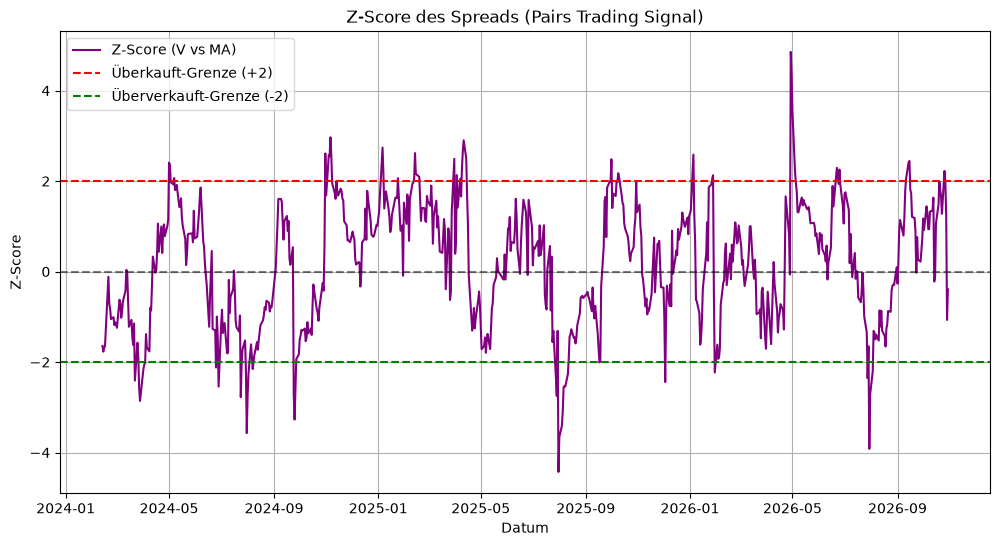

In [30]:
spread = data_norm['V'] - data_norm['MA']

window = 30
rolling_mean = spread.rolling(window=window).mean()
rolling_std = spread.rolling(window=window).std()

zscore = (spread - rolling_mean) / rolling_std

plt.figure(figsize=(12, 6))
plt.plot(zscore, label='Z-Score (V vs MA)', color='purple')
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.axhline(2.0, color='red', linestyle='--', label='Überkauft-Grenze (+2)')
plt.axhline(-2.0, color='green', linestyle='--', label='Überverkauft-Grenze (-2)')
plt.title('Z-Score des Spreads (Pairs Trading Signal)')
plt.xlabel('Datum')
plt.ylabel('Z-Score')
plt.legend()
plt.grid(True)
plt.show()

# Z-Score > +2: V ist im Vergleich zu MA zu teuer gelaufen -> Bot verkauft V (bzw. geht Short) und kauft MA (Long).
# Z-Score < -2: MA ist im Vergleich zu V zu teuer gelaufen -> Bot kauft V und verkauft MA.

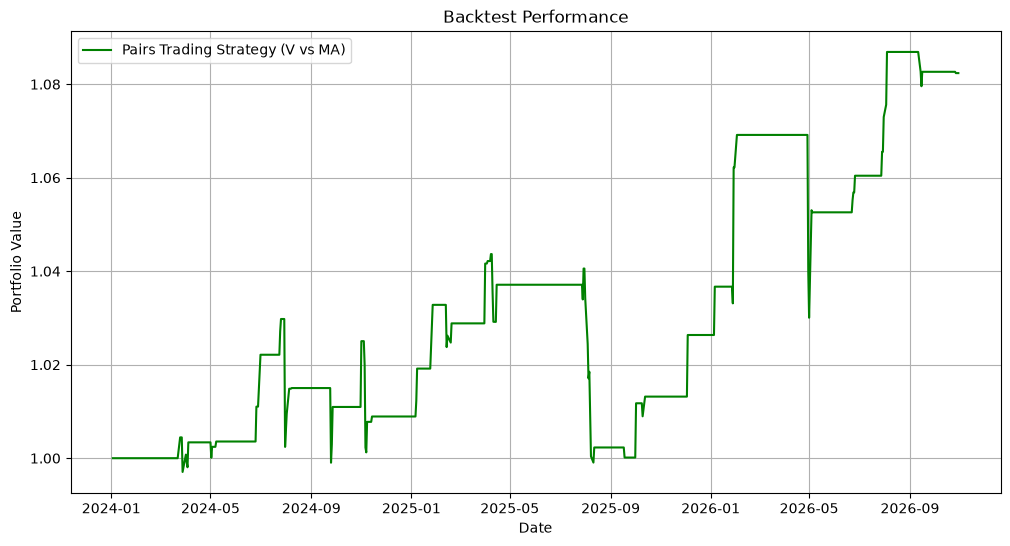

Total strategy return: 8.24%


In [ ]:
# Z-Score measures how many standard deviations the spread is from its mean.
# Position flag (+1/-1/0) acts as a directional multiplier for spread returns.

# Generate trading signals
signals = pd.DataFrame(index=zscore.index)
signals['position'] = 0

# Z-Score > 2: KO outperformed -> Short KO / Long PEP (Signal: -1)
signals.loc[zscore > 2.0, 'position'] = -1
# Z-Score < -2: PEP outperformed -> Long KO / Short PEP (Signal: 1)
signals.loc[zscore < -2.0, 'position'] = 1
# Mean reversion (Z-Score between -0.5 and 0.5) -> Close position (0)
signals.loc[(zscore >= -0.5) & (zscore <= 0.5), 'position'] = 0

# Hold positions (Forward fill until a new signal occurs)
signals['position'] = signals['position'].ffill().fillna(0)

# Calculate returns (Daily price changes of the stocks)
daily_returns = data.pct_change()
# Strategy return: Previous day's position multiplied by the difference in returns
strategy_returns = signals['position'].shift(1) * (daily_returns['V'] - daily_returns['MA'])

# Calculate cumulative performance (Initial capital = 1.0 or 100%)
cumulative_strategy = (1 + strategy_returns.dropna()).cumprod()

# Plot the results
plt.figure(figsize=(12, 6))
plt.plot(cumulative_strategy, label='Pairs Trading Strategy (V vs MA)', color='green')
plt.title('Backtest Performance')
plt.xlabel('Date')
plt.ylabel('Portfolio Value')
plt.legend()
plt.grid(True)
plt.show()

# Print key metrics
total_return = (cumulative_strategy.iloc[-1] - 1) * 100
print(f"Total strategy return: {total_return:.2f}%")

### Risk Management & Safeguards in the Backtest

Here is a brief overview of the built-in protections used in the trading script:

* **Stop-Loss (`abs(z) > 3.0`):** 
  Triggers if the spread moves too far against your position (Z-score exceeds 3.0). It cuts losses early to prevent prolonged drawdowns if the assets decouple permanently.
* **Time-Based Exit (`days_in_trade >= 15`):** 
  Closes the trade automatically if it fails to revert to the mean within 15 trading days. This frees up capital for better market opportunities.
* **Mean Reversion Target (`-0.5 <= z <= 0.5`):** 
  The standard exit condition. It closes the position once the Z-score normalizes back to the historical center.

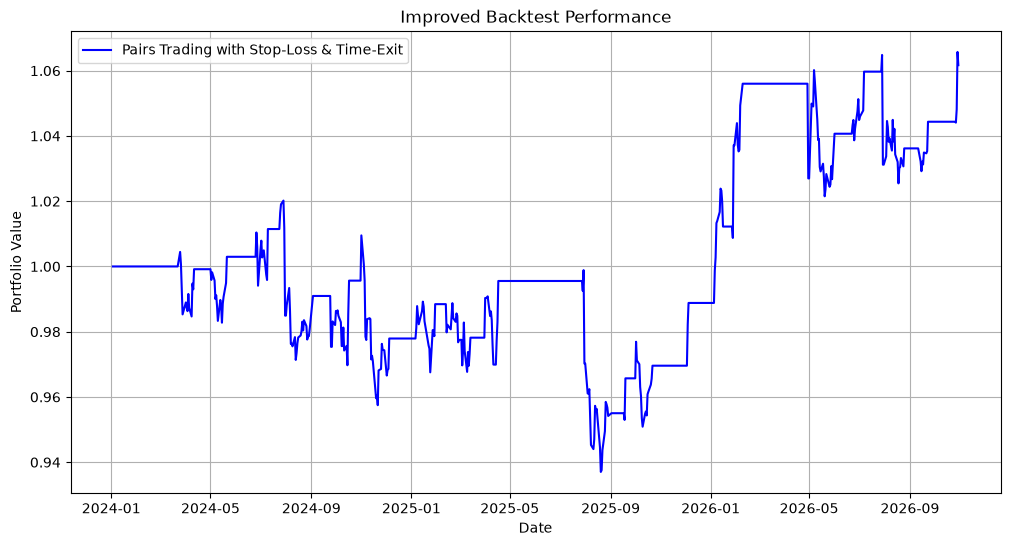

Total strategy return (optimized): 6.17%


In [ ]:
daily_returns = data.pct_change()

positions = []
current_position = 0
days_in_trade = 0

for i in range(len(zscore)):
    z = zscore.iloc[i]
    
    # Skip if Z-score is NaN (e.g., first 30 rows due to rolling window)
    if np.isnan(z):
        positions.append(0)
        continue
        
    if current_position == 0:
        # Look for entry signals
        if z > 2.0:
            current_position = -1  # Short V / Long MA
            days_in_trade = 0
        elif z < -2.0:
            current_position = 1   # Long V / Short MA
            days_in_trade = 0
    else:
        # We are in a trade, check exit conditions
        days_in_trade += 1
        
        # Exit condition 1: Mean Reversion (back to normal range)
        hit_mean = (-0.5 <= z <= 0.5)
        
        # Exit condition 2: Stop-Loss (Spread blew out too far against us, e.g., abs(z) > 3.0)
        hit_stop_loss = (abs(z) > 3.0)
        
        # Exit condition 3: Time-based exit (max 30 days in trade)
        hit_time_limit = (days_in_trade >= 30)
        
        # If any exit condition is met, close the position
        if hit_mean or hit_stop_loss or hit_time_limit:
            current_position = 0
            days_in_trade = 0
            
    positions.append(current_position)

# Convert positions list to a pandas Series
signal_series = pd.Series(positions, index=zscore.index)

strategy_returns = signal_series.shift(1) * (daily_returns['V'] - daily_returns['MA'])
cumulative_strategy = (1 + strategy_returns.dropna()).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(cumulative_strategy, label='Pairs Trading with Stop-Loss & Time-Exit', color='blue')
plt.title('Improved Backtest Performance')
plt.xlabel('Date')
plt.ylabel('Portfolio Value')
plt.legend()
plt.grid(True)
plt.show()

total_return = (cumulative_strategy.iloc[-1] - 1) * 100
print(f"Total strategy return (optimized): {total_return:.2f}%")